In [ ]:
%%html
<center><marquee style='width: 60%; color: blue;'><b>✌ ¡Hola a todos! Hoy es una clase importante ✌ </b></marquee><center>

<table>
        <td>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="400"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Regresión Logística </p> Árboles de Decisión </p> Curva ROC </FONT>         </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Machine Learning </p></tp>
            <tp><p style="font-size:115%;text-align:center">Diplomado 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>




En este notebook trabajaremos dos modelos importantes:

- Regresión logística

- Árboles de Decisión

y además la curva ROC y su área bajo la curva.

A continuación veremos los elementos generales de estos modelos

# <FONT SIZE=5 COLOR="purple"> 1. Regresión Logística </FONT>

- Usamos regresión logística para estudiar la probabilidad de una variable categórica cualitativa (por ejemplo, dicotómica)  en función de una o más variables cuantitativas.

- En otras palabras, la regresión logística no permite clasificar directamente, pero si permite determinar una probabilidad de pertenecer a un grupo determinado de la variable categórica. Y luego, de acuerdo con esa probabilidad, tomar una decisión de asignación.

<FONT SIZE=4 COLOR="red"> Motivación al modelo </FONT>

Supongamos que tenemos una variable categórica con dos clase, que las llamaremos $\{0, 1\}$. Entonces, si tratamos de buscar un modelo lineal de la forma

$$y = \beta_0 +\beta_1 x_1 +\epsilon$$

donde $y$ es una variable binaria, no sería un bueno modelo ya que la izquierda de la expresión es continua. Luego, podríamos pensar en no tener una relación directa, sino vía la probabilidad, así:

$$P(y_i=1 \mid X = x_i)= \beta_0+\beta_1x_i$$

Cuando intentamos usar mínimos cuadrados, es fácil ver que el modelo no funciona ya que predecimos valores mayores que 1 y menores que 0.

<center><img src="https://github.com/Fabian830348/cursos/blob/0da91b828112d77dbddb387cbb7043ab8a78f252/Imagen/log1.png?raw=true" alt="centered image" width="500" height="400"></center>

podemos observar que este modelo no se ajusta a los datos. Más aún, si tratamos de predecir un valor, como $x=1.1$, al tratarse de una probabilidad, este valor no tiene sentido, pues es negativo.

Entonces, buscaremos una función cumpla lo siguiente

- $P(y_i=1 \mid X = x_i) = f(\beta_0 + \beta_1 x_i)$

- $P(y_i=1 \mid  x_i)$ sea creciente en $x$ para $\beta_1>0$.

- $P(y_i=1 \mid  x_i)$ sea decreciente en $x$ para $\beta_1<0$.

- $0 \leq P(y_i=1 \mid  x_i) \leq 1$ para todo valor de $x_i$.

Se puede ver rápidamente que la función debería tener una forma de S. A esta función se le denomina función sigmoide y es la base del modelo logístico

$$f(x)= \dfrac{e^x}{1+e^x}$$

La gráfica de esta función es:

<center><img src="https://github.com/Fabian830348/cursos/blob/0da91b828112d77dbddb387cbb7043ab8a78f252/Imagen/log2.png?raw=true" alt="centered image" width="500" height="400"></center>

Así pues, tenemos una expresión de la forma

$$P(y_i=1 \mid  X = x_i)= \dfrac{e^{\beta_0+\beta_1x_i}}{1+e^{\beta_0+\beta_1x_i}}$$

Una vez tengamos esta probabilidad se establece un umbral. Por defecto es 0.5, entonces

- Si $P(y_i=1 \mid  X = x_i) \geq  0.5$ entonces el valor $x_i$ es asignado a 1.

- Si $P(y_i=1 \mid  X = x_i) < 0.5$ entonces el valor $x_i$ es asignado a 0.


# <FONT SIZE=5 COLOR="purple"> 2. Ejemplo Práctico </FONT>

- En esta sección trabajaremos el ejemplo del *notebook_2*

- Iniciaremos indicando las librerías que debemos usar.

## <FONT SIZE=4 COLOR="blue"> 2.1 Librerías de trabajo </FONT>

In [65]:
# Manipulación de data.frames
import pandas       as pd
import numpy        as np

# Librerías para Gráficos
import matplotlib.pyplot  as plt
import seaborn            as sns
import plotly.express     as px

# Librerías para datos de entrenamiento y prueba
from sklearn.model_selection    import train_test_split

# Para preprocesamiento/escalar los datos
from sklearn.preprocessing      import StandardScaler, MinMaxScaler

# modelos de clasificación
from sklearn.neighbors          import KNeighborsClassifier
from sklearn.linear_model       import LogisticRegression
from sklearn.tree               import DecisionTreeClassifier

# Métricas de evaluación
from sklearn                    import metrics
from sklearn.metrics            import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics            import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score
from imblearn.metrics           import specificity_score

# validación cruzada
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline        import Pipeline

# para hacer la curva ROC
from sklearn.metrics            import roc_auc_score
from sklearn.metrics            import roc_curve

# Optimización de hiperparámetros
from sklearn.model_selection    import GridSearchCV

# Para ignorar los warnings
import warnings
warnings.filterwarnings("ignore")

## <FONT SIZE=4 COLOR="blue"> 2.2 Contexto del problema </FONT>

Una empresa desea desarrollar un modelo de Machine Learning que permita predecir si un empleado renunciará a su puesto de trabajo, utilizando información relacionada con sus características personales y condiciones laborales.

Para ello, se dispone de un conjunto de datos de 5.000 empleados que incluye variables como edad, antigüedad, salario, horas de trabajo, distancia al lugar de trabajo, satisfacción laboral y oportunidades de ascenso, entre otras. El objetivo es construir un modelo de clasificación binaria que permita identificar patrones asociados con la renuncia laboral y estimar la probabilidad de que un empleado abandone la organización.

```python
https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_diplomado.csv
```



El conjunto de datos contiene 10 variables predictoras y una variable objetivo.

| Variable | Descripción | Tipo |
|---|---|---|
| Edad | Edad del empleado en años. | Numérica |
| Antiguedad_anios | Tiempo que lleva trabajando en la empresa, en años. | Numérica |
| Salario_mensual_COP | Salario mensual del empleado en pesos colombianos. | Numérica |
| Horas_semanales | Número de horas trabajadas por semana. | Numérica |
| Distancia_trabajo_km | Distancia entre la vivienda y el lugar de trabajo, en kilómetros. | Numérica |
| Satisfaccion_laboral | Nivel de satisfacción con el trabajo, en una escala de 1 a 5. | Ordinal |
| Balance_vida_trabajo | Percepción del equilibrio entre la vida personal y laboral, en una escala de 1 a 5. | Ordinal |
| Anios_sin_ascenso | Número de años transcurridos desde el último ascenso. | Numérica |
| Trabajo_remoto | Indica si el empleado trabaja de forma remota: 0 = No, 1 = Sí. | Categórica binaria |
| Horas_extra | Indica si el empleado realiza horas extra: 0 = No, 1 = Sí. | Categórica binaria |
| Renuncia | Variable objetivo. Indica si el empleado renuncia: 0 = Permanece, 1 = Renuncia. | Categórica binaria |

Desarrollar y evaluar un modelo de clasificación binaria que permita predecir la renuncia laboral de un empleado a partir de las 10 variables predictoras, utilizando métricas como accuracy, precision, recall, F1-score y matriz de confusión.

Pregunta de investigación: ¿Es posible predecir la renuncia de un empleado a partir de sus características personales y condiciones laborales mediante algoritmos de Machine Learning?



## <FONT SIZE=4 COLOR="blue"> 2.3 Importar los datos </FONT>

Lo primero que haremos es importar los datos que están en el siguiente link o pueden ser descargados de la página de Kaggle.

https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_diplomado.csv

In [36]:
empleados= pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_diplomado.csv")

## <FONT SIZE=4 COLOR="blue"> 2.4 Exploración rápida de los datos </FONT>

Antes de hacer cualquier modelo de machine learning o análisis similar es fundamental entender y explorar las variables del conjunto de datos.

In [37]:
# cabeza de los datos (primeros)
empleados.head()

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
0,50,7,3671886.43,NaN,44.86,3,3,0.0,0,0,1
1,25,6,3223787.18,38.49,2.46,3,2,6.0,0,0,0
2,52,21,5838929.54,46.50,57.24,1,2,3.0,0,0,1
3,34,16,3335062.80,58.91,30.15,5,2,6.0,0,0,1
4,34,0,1633510.55,47.95,21.02,2,4,2.0,1,1,1


In [38]:
# revisar la información de los datos
empleados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Edad                  5000 non-null   int64  
 1   Antiguedad_anios      5000 non-null   object 
 2   Salario_mensual_COP   5000 non-null   float64
 3   Horas_semanales       4999 non-null   float64
 4   Distancia_trabajo_km  5000 non-null   object 
 5   Satisfaccion_laboral  5000 non-null   int64  
 6   Balance_vida_trabajo  5000 non-null   int64  
 7   Anios_sin_ascenso     4999 non-null   float64
 8   Trabajo_remoto        5000 non-null   int64  
 9   Horas_extra           5000 non-null   int64  
 10  Renuncia              5000 non-null   int64  
dtypes: float64(3), int64(6), object(2)
memory usage: 429.8+ KB


observamos dos cosas importante:

1. Hay datos faltantes en las variables `Horas_semanales` y `Anios_sin_ascenso`

2. Hay inconsistencias en `Distancia_trabajo_km` y `Antiguedad_anios`

## <FONT SIZE=4 COLOR="blue"> 2.5 Preprocesar los datos </FONT>

Como hay inconsistencias, primero debemos arreglarlas

Para la primera eliminamos los `Na's`

In [39]:
# contar los datos faltantes
empleados.isna().sum()

,0
Edad,0
Antiguedad_anios,0
Salario_mensual_COP,0
Horas_semanales,1
Distancia_trabajo_km,0
Satisfaccion_laboral,0
Balance_vida_trabajo,0
Anios_sin_ascenso,1
Trabajo_remoto,0
Horas_extra,0


Los vamos a eliminar

In [40]:
# eliminar los datos faltantes
empleados = empleados.dropna()

In [41]:
empleados.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4998 entries, 1 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Edad                  4998 non-null   int64  
 1   Antiguedad_anios      4998 non-null   object 
 2   Salario_mensual_COP   4998 non-null   float64
 3   Horas_semanales       4998 non-null   float64
 4   Distancia_trabajo_km  4998 non-null   object 
 5   Satisfaccion_laboral  4998 non-null   int64  
 6   Balance_vida_trabajo  4998 non-null   int64  
 7   Anios_sin_ascenso     4998 non-null   float64
 8   Trabajo_remoto        4998 non-null   int64  
 9   Horas_extra           4998 non-null   int64  
 10  Renuncia              4998 non-null   int64  
dtypes: float64(3), int64(6), object(2)
memory usage: 468.6+ KB


Ahora, debemos revisar por qué tenemos datos tipos `object`

In [42]:
# revisar la variable Antiguedad_anios
empleados["Antiguedad_anios"].unique()

array(['6', '21', '16', '0', '24', '5', '18', '8', '7', '22', '26', '15',
       '14', '10', '2', '27', '30', '9', '13', '3', '11', '25', '23',
       '12', '29', '20', '19', '17', '1', '4', '28', ' '], dtype=object)

Aparecen entre comillas, eso quiere decir que en la variable hay texto o caracteres especiales.

In [43]:
# Intentar convertir a numérico
numerica = pd.to_numeric(empleados["Antiguedad_anios"], errors='coerce')

# Identificar valores que no pudieron convertirse
problemas = empleados[numerica.isna() & empleados["Antiguedad_anios"].notna()]

display(problemas)

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
170,44,,1994223.53,40.35,4.10,4,5,3.0,0,1,1


In [44]:
# Intentar convertir a numérico Distancia_trabajo_km
numerica = pd.to_numeric(empleados["Distancia_trabajo_km"], errors='coerce')

# Identificar valores que no pudieron convertirse
problemas_2 = empleados[numerica.isna() & empleados["Distancia_trabajo_km"].notna()]

display(problemas_2)

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
21,27,9,3862356.36,40.31,,4,1,3.0,0,1,1


In [45]:
# eliminar los registros 21 y 170
empleados = empleados.drop([21,170])

In [46]:
# cambiar las variables a numéricas
empleados["Antiguedad_anios"] = pd.to_numeric(empleados["Antiguedad_anios"])
empleados["Distancia_trabajo_km"] = pd.to_numeric(empleados["Distancia_trabajo_km"])

In [47]:
empleados.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4996 entries, 1 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Edad                  4996 non-null   int64  
 1   Antiguedad_anios      4996 non-null   int64  
 2   Salario_mensual_COP   4996 non-null   float64
 3   Horas_semanales       4996 non-null   float64
 4   Distancia_trabajo_km  4996 non-null   float64
 5   Satisfaccion_laboral  4996 non-null   int64  
 6   Balance_vida_trabajo  4996 non-null   int64  
 7   Anios_sin_ascenso     4996 non-null   float64
 8   Trabajo_remoto        4996 non-null   int64  
 9   Horas_extra           4996 non-null   int64  
 10  Renuncia              4996 non-null   int64  
dtypes: float64(4), int64(7)
memory usage: 468.4 KB


Ahora, las estadísticas descriptivas.

In [48]:
# estadísticos descriptivos
empleados.describe()

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,Renuncia
count,4996.000000,4996.000000,4.996000e+03,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000,4996.000000
mean,42.179944,11.946757,3.693091e+06,43.168713,32.790504,3.014412,2.978183,4.930344,0.494996,0.502802,0.501801
std,13.658169,8.166214,1.552922e+06,6.776675,18.782772,1.412299,1.413266,3.172888,0.500025,0.500042,0.500047
min,19.000000,0.000000,1.400000e+06,30.000000,0.520000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,5.000000,2.449955e+06,38.470000,16.177500,2.000000,2.000000,2.000000,0.000000,0.000000,0.000000
50%,42.000000,11.000000,3.572854e+06,43.110000,33.015000,3.000000,3.000000,5.000000,0.000000,1.000000,1.000000
75%,54.000000,18.000000,4.765366e+06,47.810000,49.142500,4.000000,4.000000,8.000000,1.000000,1.000000,1.000000
max,65.000000,30.000000,9.305460e+06,65.000000,64.990000,5.000000,5.000000,10.000000,1.000000,1.000000,1.000000


Ahora revisamos la variable objetivo

In [49]:
# contar las categorias de la variable resultado
empleados["Renuncia"].value_counts()

,count
Renuncia,
1,2507
0,2489


Los datos están balanceados y eso es bueno para el entrenamiento de los modelos

In [50]:
# sirve para evaluar modelos de clasificación binaria.
def evaluacion_modelo(modelo, X_train, y_train, X_test, y_test, nombre_modelo = "modelo",graficar = True):
  # definir las predicciones en conjuntos de train y test
  y_pred_train = modelo.predict(X_train)
  y_pred_test  = modelo.predict(X_test)
  # matrices de confusión
  if graficar :
    # Calcular matrices de confusión
    cm_train = confusion_matrix(y_train, y_pred_train)
    cm_test = confusion_matrix(y_test, y_pred_test)
    # ejes para gráficas
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    # matriz de confusión en train
    sns.heatmap(pd.DataFrame(cm_train),                # data.frame
                  annot=True,                          # colocar números de las cajitas
                  annot_kws = {'size':20},             # tamaño de la letra
                  cmap="YlOrRd",                       # color de la letra 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu'
                  fmt='g',                             # para que salgan los número no : notación científica
                  ax=axes[0])
    axes[0].set_title(f'Matriz de Confusión - Train-{nombre_modelo}', fontsize=14)
    axes[0].set_xlabel('Predicciones')
    axes[0].set_ylabel('Valores Reales')
    # matriz de confusión en test
    sns.heatmap(pd.DataFrame(cm_test),
              annot=True,
              fmt='g',
              cmap='YlOrRd',
              annot_kws={'size':20},
              ax=axes[1])
    axes[1].set_title(f'Matriz de Confusión - Test-{nombre_modelo}', fontsize=14)
    axes[1].set_xlabel('Predicciones')
    axes[1].set_ylabel('Valores Reales')
    plt.tight_layout()
    plt.show()
  # metricas en train
  metrics=["accuracy", "recall" , "specificity", "precision", "f1"]
  # valores
  values_train = [accuracy_score(y_train,y_pred_train),
          recall_score(y_train,y_pred_train),
          specificity_score(y_train,y_pred_train),
          precision_score(y_train,y_pred_train),
          f1_score(y_train,y_pred_train)]
  values_test = [accuracy_score(y_test,y_pred_test),
          recall_score(y_test,y_pred_test),
          specificity_score(y_test,y_pred_test),
          precision_score(y_test,y_pred_test),
          f1_score(y_test,y_pred_test)]

  df = pd.DataFrame({f"{nombre_modelo}_train" : values_train,
                      f"{nombre_modelo}_test" : values_test}, index = metrics)
  return df


## <FONT SIZE=4 COLOR="blue"> 2.6 Modelo de Regresión Logística </FONT>

Vamos a plantear el modelo **regresión logística** vecinos más cercanos

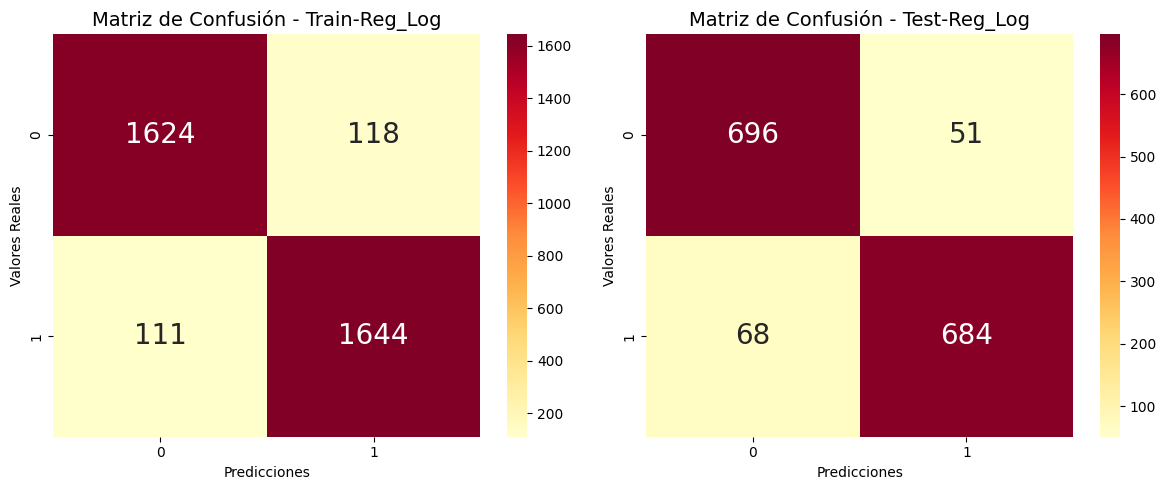

,Reg_Log_train,Reg_Log_test
accuracy,0.934515,0.920614
recall,0.936752,0.909574
specificity,0.932262,0.931727
precision,0.933031,0.930612
f1,0.934888,0.919973


In [51]:
# 1. Seleccionar variable objetivo y predictoras
# la variable objetivo
y = empleados["Renuncia"]
# las variables predictoras
X = empleados.drop("Renuncia", axis=1)

# 2. Dividir en dos conjuntos: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    stratify = y,             # garantiza que los resultados se distribuyan igual
                                                    random_state = 123,        # semilla para que al ejecutar siempre de igual
                                                    test_size = 0.3)          # tamaño del conjunto de prueba (también se puede train)


# 3. escalar las variables.
# definimos la función para escalar
escalar = StandardScaler()
# lo aplicamos a los conjuntos (s: scaler)
X_train_s = escalar.fit_transform(X_train)
X_test_s = escalar.transform(X_test)

# 4. Generar el modelo
# definir el modelo
# defecto toma 5 vecinos
modelo_log = LogisticRegression()
# entrenar el modelo
modelo_log.fit(X_train_s,y_train)

# 5. Evaluar el modelo
evaluacion_log = evaluacion_modelo(modelo_log, X_train_s, y_train, X_test_s, y_test, nombre_modelo = "Reg_Log",graficar = True)
evaluacion_log


Otra forma de revisar las métricas es con el *classification_report*

In [52]:
y_pred = modelo_log.predict(X_test_s)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.91      0.93      0.92       747
           1       0.93      0.91      0.92       752

    accuracy                           0.92      1499
   macro avg       0.92      0.92      0.92      1499
weighted avg       0.92      0.92      0.92      1499



Ahora miramos validación cruzada

In [53]:
# definimos el pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("reg_log", LogisticRegression())
])

# Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10,
                     shuffle=True,
                     random_state=42)

# Evaluar el pipeline con validación cruzada
resultados = cross_val_score(pipeline,
                             X_train,
                             y_train,
                             cv=cv,
                             scoring="accuracy")

print("Accuracy por partición:", resultados)
print(f"Accuracy promedio: {resultados.mean():.4f}")
print(f"Desviación estándar: {resultados.std():.4f}")

Accuracy por partición: [0.92       0.93142857 0.94       0.92857143 0.92       0.93428571
 0.92857143 0.93982808 0.9226361  0.93409742]
Accuracy promedio: 0.9299
Desviación estándar: 0.0070


Obtenemos en promedio 0.92 de *Accuracy*

# <FONT SIZE=5 COLOR="purple"> 3. Árboles de Decisión </FONT>

- El enfoque de clasificación y regresión vía árboles (CART, classification and regression tree) fue desarrollado por Breiman et al. (1984).

- Un árbol de decisión es una estructura que incluye un ***nodo raíz, nodos principales, ramas y nodos hoja***. Cada nodo interno denota una prueba sobre un atributo, cada rama denota el resultado de una prueba y cada nodo hoja contiene una etiqueta de clase. El nodo superior del árbol también es llamado: **nodo raíz**.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree1.png?raw=true" alt="centered image" width="500" height="350"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

Los términos que intervienen en el algoritmo de árbol de decisión son los siguientes

- ***Nodo raíz:***: Es el nodo inicial del árbol.

- ***División:*** Es un proceso de división de un nodo en dos o más subnodos.

- ***Nodo de decisión***: Cuando un subnodo se divide en otros subnodos, se denomina nodo de decisión.

- ***Nodo hoja/terminal***: Son los nodos que no se dividen más.

- ***Rama/Subárbol***:  Una subsección de un árbol completo que inicia con un nodo principal.

- ***Profundidad:*** Es el número de niveles de decisión en el árbol.

- ***Poda***: Es el proceso de eliminar nodos de decisión con el fin de hacer el árbol más pequeño

Esta técnica de machine learning toma una serie de decisiones binarias en forma de árbol. Los nodos intermedios (las ramas) representan soluciones y los nodos finales (las hojas) nos dan la predicción que buscamos.

Para seleccionar las condiciones que conforman el árbol se usan dos elementos que se describirán más adelante.

  - Indice de Gini
  - Ganancia de Información (Entropía)


Lo primero que debemos indicar es que el algoritmo se basa en una serie de decisiones binarias, que gráficamente, no es más que una división de una región del plano donde están los datos.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree2.png?raw=true" alt="centered image" width="650" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

Esta división se hace con el fin de separar un conjunto de puntos en las clases correspondientes. Consideremos el siguiente conjunto de puntos:

$$\{(x_i,y_i) \mid i = 1,2,3, \dots 29\}$$

<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree13.png?raw=true" alt="centered image" width="650" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

Buscamos hacer divisiones rectangulares con el fin de separar los puntos. Para esto debemos iniciar con una condición, pero ¿cómo se hace esto?

Para responder está pregunta debemos hacer una grilla o cuadrícula tomando como referencia puntos entre cada $(x_i,x_{i+1}$) y $(y_i,y_{i+1})$.Por lo general se toma el punto medio

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree3.png?raw=true" alt="centered image" width="650" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

Ahora, debemos determinar cuál condición $x \leq x_i$ o $y \leq y_j$ es más apropiada para iniciar. Esta condición nos dará el nodo raíz que es el inicio del algoritmo.

Es en este punto donde debemos tener un criterio de decisión. Para ello hay dos alternativas: usar el índice de Gini o la Entropía, con el fin de determinar la mejor condición.

- El índice de Gini dice que, si seleccionamos al azar dos elementos de una población, deben ser de la misma clase y la probabilidad de que esto ocurra es 1 si la población es pura. En otras palabras, este índice permite determinar si un conjunto de puntos es homogéneo o no.

- Este índice funciona con la variable objetivo categórica "Éxito" o "Fracaso". Sólo realiza divisiones binarias.

*Cuanto menor sea el valor de Gini, mayor será la homogeneidad.*

- El **índice de Gini** está dado en general como:

$$Gini = 1-\sum \limits_{k=1}^{n}p_k^2$$

donde $p_k$ es la probabilidad de seleccionar un objeto de la clase $k$ en un determinado nodo.

Veamos un ejemplo de dos condiciones:

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree14.png?raw=true" alt="centered image" width="650" height="350"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

Ahora bien, para determinar si elegimos una condición o no, usaremos el concepto de *impureza*, que se define de la siguiente manera

$$\text{Impureza de un nodo} = (Gini) \times (\text{Ponderacion de los nodos})$$

Supongamos que en nuestro ejemplo ( de los puntos dados arriba) queremos saber cuál condición es mejor, es decir, tiene un nivel de impureza menor.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree5.png?raw=true" alt="centered image" width="650" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

Es importante resaltar que el algoritmo compara todas las impurezas y escoje la menor. En ese sentido, la función de costo para los árboles de clasificación es:

$$\text{función de costo} = 1-\sum \limits_{k=1}^{n}p_k^2$$

Partiendo de esta condición, comenzamos la división en el árbol buscando minimizar esta función.

En las siguientes imágenes se observan las divisiones del árbol para diferentes valores

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree4.png?raw=true" alt="centered image" width="650" height="350"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree6.png?raw=true" alt="centered image" width="650" height="350"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/tree/tree7.png?raw=true" alt="centered image" width="650" height="350"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>

**Observación:** El método de árboles de decisión busca minimizar el índice de Gini y esto se puede lograr dividiendo el árbol de manera exhaustiva. Es decir, practicamente que cada punto este en una región. Pero esto es malo, ya que estamos *sobreajustando* el modelo. En otras palabras, el modelo clasifica perfectamente los datos del conjunto de entrenamiento pero no clasificará bien en los datos de prueba.

Ahora, hacemos el modelo

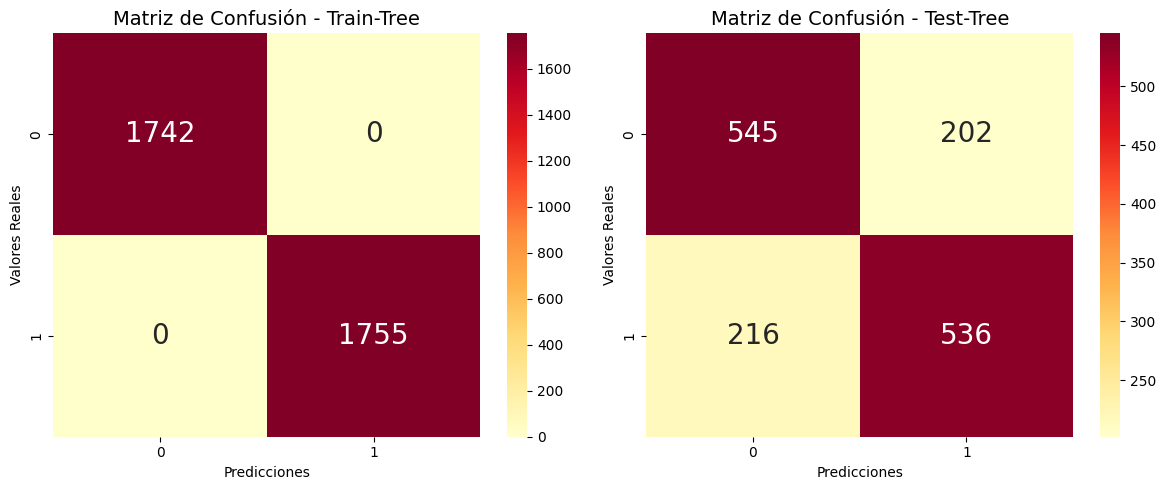

,Tree_train,Tree_test
accuracy,1.0,0.721147
recall,1.0,0.712766
specificity,1.0,0.729585
precision,1.0,0.726287
f1,1.0,0.719463


In [54]:
# 1. Seleccionar variable objetivo y predictoras
# la variable objetivo
y = empleados["Renuncia"]
# las variables predictoras
X = empleados.drop("Renuncia", axis=1)

# 2. Dividir en dos conjuntos: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    stratify = y,             # garantiza que los resultados se distribuyan igual
                                                    random_state = 123,        # semilla para que al ejecutar siempre de igual
                                                    test_size = 0.3)          # tamaño del conjunto de prueba (también se puede train)

# 3. Escalar las variables
escalar = StandardScaler()
X_train_s = escalar.fit_transform(X_train)
X_test_s = escalar.transform(X_test)

# 4. Mefinir el modelo (hiperparámetros)
modelo_tree = DecisionTreeClassifier(random_state=123)

# 5. Entrenar el modelo
modelo_tree.fit(X_train,y_train)

# 6. Evaluar el modelo
evaluacion_tree = evaluacion_modelo(modelo_tree, X_train, y_train, X_test, y_test, nombre_modelo = "Tree",graficar = True)
evaluacion_tree

Hagamos validación cruzada

In [55]:
# definimos el pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("tree", DecisionTreeClassifier())
])

# Configurar validación cruzada estratificada
cv = StratifiedKFold(n_splits=10,
                     shuffle=True,
                     random_state=42)

# Evaluar el pipeline con validación cruzada
resultados = cross_val_score(pipeline,
                             X_train,
                             y_train,
                             cv=cv,
                             scoring="accuracy")

print("Accuracy por partición:", resultados)
print(f"Accuracy promedio: {resultados.mean():.4f}")
print(f"Desviación estándar: {resultados.std():.4f}")

Accuracy por partición: [0.73428571 0.71714286 0.74857143 0.71714286 0.76857143 0.75714286
 0.72571429 0.75931232 0.74212034 0.71919771]
Accuracy promedio: 0.7389
Desviación estándar: 0.0181


Vamos a recordar el modelo *knn*

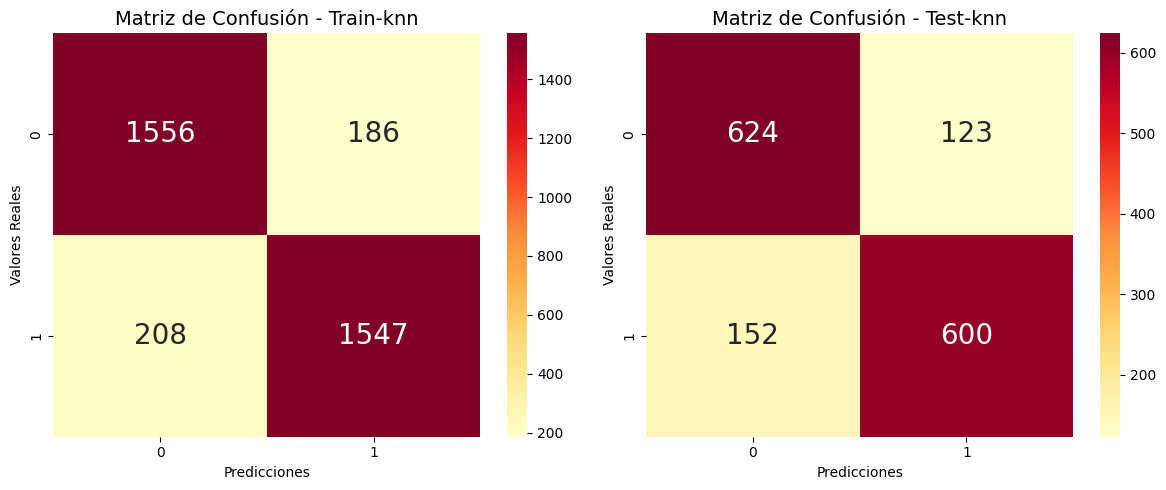

,knn_train,knn_test
accuracy,0.887332,0.816544
recall,0.881481,0.797872
specificity,0.893226,0.835341
precision,0.892672,0.829876
f1,0.887041,0.813559


In [56]:
# 1. Seleccionar variable objetivo y predictoras
# la variable objetivo
y = empleados["Renuncia"]
# las variables predictoras
X = empleados.drop("Renuncia", axis=1)

# 2. Dividir en dos conjuntos: entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    stratify = y,             # garantiza que los resultados se distribuyan igual
                                                    random_state = 123,        # semilla para que al ejecutar siempre de igual
                                                    test_size = 0.3)          # tamaño del conjunto de prueba (también se puede train)

# 3. Escalar las variables
escalar = StandardScaler()
X_train_s = escalar.fit_transform(X_train)
X_test_s = escalar.transform(X_test)

# 4. Mefinir el modelo (hiperparámetros)
modelo_knn = KNeighborsClassifier()

# 5. Entrenar el modelo
modelo_knn.fit(X_train_s,y_train)

# 6. Evaluar el modelo
evaluacion_knn = evaluacion_modelo(modelo_knn, X_train_s, y_train, X_test_s, y_test, nombre_modelo = "knn",graficar = True)
evaluacion_knn

# <FONT SIZE=5 COLOR="purple"> 4. Métricas de los tres modelos</FONT>

In [57]:
# Comparación de los tres modelos
comparacion = pd.DataFrame({
    "Regresión Logística": evaluacion_log["Reg_Log_test"],
    "Árbol de Decisión": evaluacion_tree["Tree_test"],
    "KNN": evaluacion_knn["knn_test"]
})

# Mostrar resultados en porcentaje
display((comparacion * 100).round(2))


,Regresión Logística,Árbol de Decisión,KNN
accuracy,92.06,72.11,81.65
recall,90.96,71.28,79.79
specificity,93.17,72.96,83.53
precision,93.06,72.63,82.99
f1,92.00,71.95,81.36


Ahora hacemos una representación gráfica de las métricas en los tres modelos

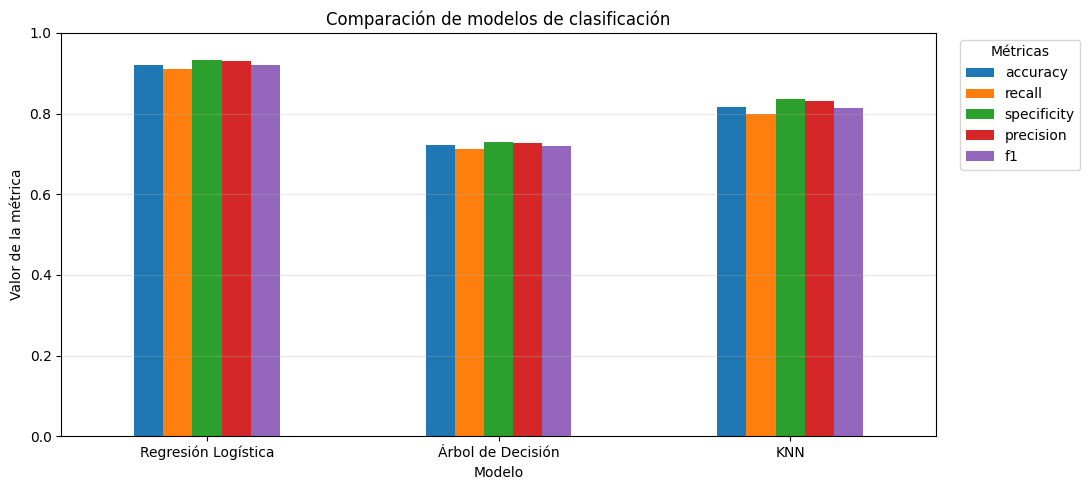

In [59]:
# Comparación gráfica de métricas en test
comparacion.T.plot(kind="bar",
                   figsize=(11, 5),
                   rot=0)

plt.title("Comparación de modelos de clasificación")
plt.ylabel("Valor de la métrica")
plt.xlabel("Modelo")
plt.ylim(0, 1)
plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [60]:
# Mejor modelo por cada métrica
mejores = pd.DataFrame({
    "Mejor modelo": comparacion.idxmax(axis=1),
    "Valor (%)": (comparacion.max(axis=1) * 100).round(2)
})

display(mejores)


,Mejor modelo,Valor (%)
accuracy,Regresión Logística,92.06
recall,Regresión Logística,90.96
specificity,Regresión Logística,93.17
precision,Regresión Logística,93.06
f1,Regresión Logística,92.00


In [61]:
sobreajuste = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Árbol de Decisión",
        "KNN"
    ],
    "Accuracy train": [
        evaluacion_log.loc["accuracy", "Reg_Log_train"],
        evaluacion_tree.loc["accuracy", "Tree_train"],
        evaluacion_knn.loc["accuracy", "knn_train"]
    ],
    "Accuracy test": [
        evaluacion_log.loc["accuracy", "Reg_Log_test"],
        evaluacion_tree.loc["accuracy", "Tree_test"],
        evaluacion_knn.loc["accuracy", "knn_test"]
    ]
})

sobreajuste["Diferencia"] = (
    sobreajuste["Accuracy train"] -
    sobreajuste["Accuracy test"]
)

display((sobreajuste.set_index("Modelo") * 100).round(2))


,Accuracy train,Accuracy test,Diferencia
Modelo,,,
Regresión Logística,93.45,92.06,1.39
Árbol de Decisión,100.00,72.11,27.89
KNN,88.73,81.65,7.08


Se observa que el mejor modelo es la regresión logística.

# <FONT SIZE=5 COLOR="purple"> 5. Curva ROC (Receiver operating characteristic) </FONT>

- *ROC* es el acrónimo de Receiver Operating Characteristics (característica operativa del receptor) y fue desarrollada en el campo de la ingeniería electrónica para medir la detección de objetos enemigos en el campo de batalla usando los radades durante la segunda guerra mundial. Fue la base para la TDS-Teoría de Detección de Señales.

- Sus aplicaciones trascendieron más allá del campo militar en áreas como la medicina, la epidemiología y en la investigación, etc.

- La curva ROC se aplica para evaluar algoritmos de *machine learning* y hacer comparación del rendimiento de estos.

- Formalmente, la ***curva ROC*** es la representación gráfica de la razón o proporción de verdaderos positivos (TPR = True positive rate) frente a la razón o proporción de falsos positivos (FPR = False positive rate) según se varía el umbral de discriminación (valor a partir del cual decidimos que un caso es un positivo).

- La curva *ROC* nos dice qué tan bueno puede distinguir el modelo entre dos cosas, por ejemplo, si un paciente tiene cáncer o no. Mejores modelos pueden distinguir con precisión entre los dos, mientras que un modelo pobre tendrá dificultades para distinguir entre los dos.

Supongamos que tenemos un modelo que predice si un paciente tiene cáncer o no. Teniendo en cuenta la matriz de confusión:

<center><img src="https://github.com/Fabian830348/cursos/blob/65ac42855edcaf2617ef7670654e61459e11060d/Clasificacion/metricas.png?raw=true" alt="centered image" width="500" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia  </FONT> <figcaption></center>
<br>
Podemos representar estos elementos en el plano cartesiano de la siguiente manera.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/ROC/roc1.png?raw=true" alt="centered image" width="500" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia   </FONT> <figcaption></center>

- Línea azul: pacientes sanos. (sin cáncer).
- Línea Naranja: pacientes enfermos. (con cáncer).
- Para la clasificación tomamos por defecto un *umbral* de $\alpha=0.5$.
- Por encima de $\alpha=0.5$ clasificamos al paciente: *con cáncer*.
- Por debajo de $\alpha=0.5$ clasificamos al paciente: *sin cáncer*.

Ahora bien, de acuerdo con la matriz de confusión:

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/ROC/roc2.png?raw=true" alt="centered image" width="500" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia   </FONT> <figcaption></center>

- Los valores positivos por encima del umbral serán *verdaderos positivos*
- Los valores negativos por encima del umbral serán *falsos positivos*; ya que se predicen incorrectamente como positivos.
- Los valores negativos por debajo del umbral serán *verdaderos negativos*.
- Los valores positivos por debajo del umbral serán *falsos negativos*, ya que se pronostican incorrectamente como negativos.

Recordemos dos fórmulas de la matriz de confusión:  *sensibilidad* y *especificidad*.

La ***sensibilidad o recall***, es la proporción de pacientes que se identificaron correctamente por tener cáncer, es decir verdadero positivo, sobre el número total de pacientes que realmente tienen la enfermedad.

$$recall = \dfrac{VP}{VP+FN}$$

Por su parte, ***especificidad*** es la proporción de pacientes que se identificaron correctamente por no tener cáncer, verdadero negativo, sobre el número total de pacientes que no tienen la enfermedad.

$$specificity = \dfrac{VN}{VN+FP}$$

Si movemos el umbral, los valores de $VN, VP, FN, FP$ cambiarán y tendríamos clasificaciones diferentes:

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/ROC/roc3.png?raw=true" alt="centered image" width="550" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia   </FONT> <figcaption></center>

**Relación entre *recall* y *specificity* **

- Entre mayor sea el *recall* (sensibilidad) menor será la especificidad, en otras palabras, guardan una relación inversa.

- La curva ROC es la gráfica de $recall$ contra

$$1- especificidad = \dfrac{FP}{VN+FP}$$

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/4dc5beacae26450da3a6193ef145a9b90a5f5aba/ROC/roc4.PNG?raw=true" alt="centered image" width="600" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia   </FONT> <figcaption></center>

Veamos algunos casos:

- Si el umbral separa totalmente los dos conjuntos la clasificación es perfecta.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/4dc5beacae26450da3a6193ef145a9b90a5f5aba/ROC/roc5.PNG?raw=true" alt="centered image" width="600" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia   </FONT> <figcaption></center>

- Si se da la siguiente situación, el modelo es malo ya que no discrimina entre positivos y negativos.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/4dc5beacae26450da3a6193ef145a9b90a5f5aba/ROC/roc6.PNG?raw=true" alt="centered image" width="600" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia   </FONT> <figcaption></center>

Ver el siguiente vídeo

[Simulación de ROC](https://www.youtube.com/watch?v=fsgDD0pNkZ0&t=322s)

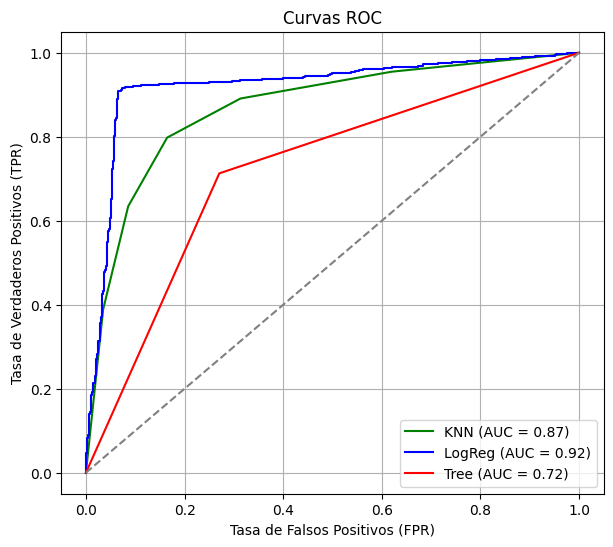

In [67]:
# veamos la curva ROC
fpr_test_knn, tpr_test_knn, _ = roc_curve(y_test, modelo_knn.predict_proba(X_test_s)[:,1])
fpr_test_log, tpr_test_log, _ = roc_curve(y_test, modelo_log.predict_proba(X_test_s)[:,1])
fpr_test_tree, tpr_test_tree, _ = roc_curve(y_test, modelo_tree.predict_proba(X_test)[:,1])

# AUC
auc_test_knn = roc_auc_score(y_test, modelo_knn.predict_proba(X_test_s)[:,1])
auc_test_log = roc_auc_score(y_test, modelo_log.predict_proba(X_test_s)[:,1])
auc_test_tree = roc_auc_score(y_test, modelo_tree.predict_proba(X_test)[:,1])

# Gráfica curva ROC
plt.figure(figsize=(7,6))
plt.plot(fpr_test_knn, tpr_test_knn, color='green', label=f'KNN (AUC = {auc_test_knn:.2f})')
plt.plot(fpr_test_log, tpr_test_log, color='blue', label=f'LogReg (AUC = {auc_test_log:.2f})')
plt.plot(fpr_test_tree, tpr_test_tree, color='red', label=f'Tree (AUC = {auc_test_tree:.2f})')


# Línea diagonal (azar)
plt.plot([0,1], [0,1], color='gray', linestyle='--')

# Detalles del gráfico
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.title("Curvas ROC")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

La curva ROC y el AUC (área bajo la curva) confirman que el mejor modelo es el de regresión logística.

Ahora haremos optimización de hiperparámetros con la regresión logística

# <FONT SIZE=5 COLOR="purple"> 6. Hiperparámetros de la regresión logística </FONT>

La regresión logística tiene los siguientes hiperparámetros

1. *penalty* : Parámetro de regularización. Es una técnica para evitar el sobreajuste (**overfitting)**

$$Funcion\_de\_Costo = Log\_Loss + Penalizacion$$

Esta penalización puede ser $L1$ que se llama Lasso y $L2$ que se llama Ridge

**Regularización *L2* (Ridge)**

Penaliza la suma de los cuadrados de los coeficientes

$$\lambda \sum \limits_{j=1}^n \beta_{j}^2$$

   - Empuja los coeficientes hacia valores pequeños, pero no los anula

   - Mantiene todas las variables del modelo.

**Regularización *L1* Lasso**

Penaliza la suma del valor absoluto de los coeficientes

$$\lambda \sum \limits_{j=1}^n |\beta_{j}|$$

   - Tiene el efecto de que algunos coeficientes se vuelven cero.

   - Selección automática de variables.

**Elastic Net : *L1+L2***

$$\lambda_1 \sum \limits_{j=1}^n \beta_{j}^2+\lambda_2 \sum \limits_{j=1}^n |\beta_{j}|$$


En resumen, la función de pérdida queda

$$ -\dfrac{1}{n}\sum \limits_{i=1}^n [y_i\log(\hat{y_i})+(1-y_i)\log(1-\hat{y_i})] + \lambda \sum \limits_{j=1}^n \beta_{j}^2$$

o

$$ -\dfrac{1}{n}\sum \limits_{i=1}^n [y_i\log(\hat{y_i})+(1-y_i)\log(1-\hat{y_i})] + \lambda \sum \limits_{j=1}^n |\beta_{j}|$$

2. *Solver*: Parámetro de optimización. Algoritmo utilizado para optimizar

 - *liblinear* : soporta L1 y L2. Para conjunto pequeños de datos.

 - *saga*: conjuntos de datos grandes. Soporta L1, L2 y Elasticnet.

 - *lbfga*: problemas multiclase con L2

 - *newtin-cg*. Es útil en multiclase.

3. Hiperparámetro *C*

En *LogisticRegression* de scikit-learn, no se usa $\lambda$ sino el inverso

$$C = \dfrac{1}{\lambda}$$

  - C grande, implica $\lambda$ pequeño: menos regularización.

  - C pequeño, implica $\lambda$ grande: más regularización.

  - C = [0.001, 0.01 , 0.1 , 1 , 10 , 100 , 1000]


El código para hacer la búsqueda en grilla es:

In [68]:
# optimización de hiperparámetros
from sklearn.pipeline import Pipeline
# Crear pipeline con escalador y modelo
pipe = Pipeline(steps=[
      ('scaler', StandardScaler()),
      ('reg_log', LogisticRegression())
      ])

# definimos los parámetros que vamos a combinar. Diccionario
grid_params = {"reg_log__penalty": ["l1", "l2"],
               "reg_log__C": [0.001, 0.01, 0.1, 1, 10, 100]}

# hacemos la búsqueda en grilla con 5-folds
Grid = GridSearchCV(pipe,                        # el modelo aplicado
                    grid_params,                 # los parámetros que van a variar
                    cv = 10,                     # el número de folds
                    verbose = 1)                 # para que imprima resultados. Posibilidades: 1,2 o 3
# Entrenar el modelo obtenido arriba
g_res = Grid.fit(X_train,y_train)

Fitting 10 folds for each of 12 candidates, totalling 120 fits


In [70]:
# el mejor accuracy
print("Mejor score: ",g_res.best_score_)
# los mejores hiperparámetros
print("Mejores hiperparámetros", g_res.best_params_)
# el mejor modelo
modelo_log_best = g_res.best_estimator_

Mejor score:  0.9313778141629145
Mejores hiperparámetros {'reg_log__C': 1, 'reg_log__penalty': 'l2'}


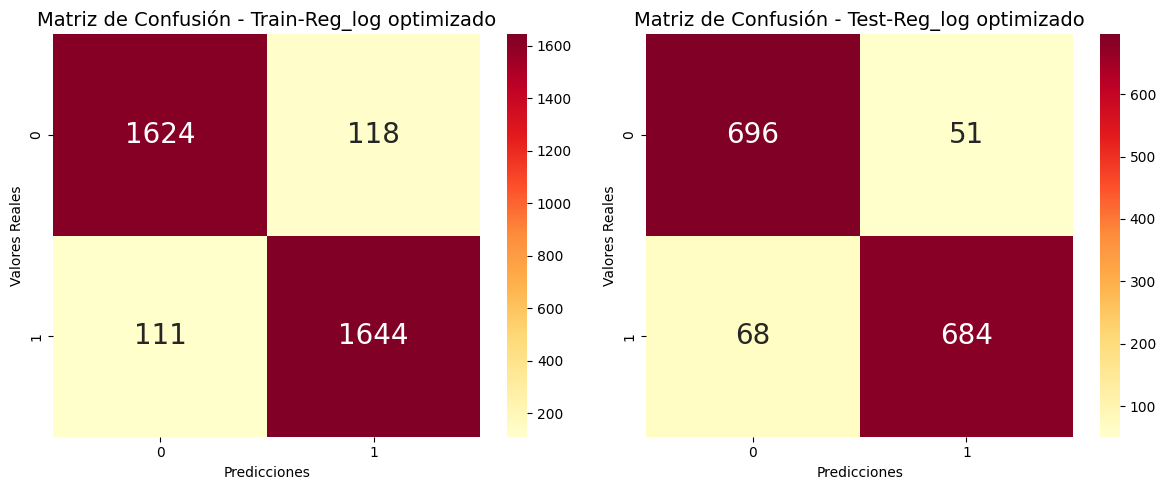

,Reg_log optimizado_train,Reg_log optimizado_test
accuracy,0.934515,0.920614
recall,0.936752,0.909574
specificity,0.932262,0.931727
precision,0.933031,0.930612
f1,0.934888,0.919973


In [71]:
# evaluar el modelo optimizado
evaluacion_modelo(modelo_log_best,X_train,y_train,X_test,y_test,nombre_modelo="Reg_log optimizado")

Ahora, vamos a hacer predicciones

# <FONT SIZE=4 COLOR="Purple"> 7. Predicciones con el modelo de Regresión logístiva </FONT>

In [72]:
empleados_predicciones = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_nuevos_50_prediccion.csv")
empleados_predicciones.head()

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra
0,39,4,3558900.55,43.97,44.00,3,1,2,0,0
1,45,4,3846442.44,47.98,13.82,4,5,0,1,1
2,34,13,4569842.15,63.78,12.27,4,5,8,0,0
3,21,2,1400000.00,47.80,29.63,1,5,2,1,1
4,63,18,4274175.30,49.11,28.82,5,2,8,1,1


In [73]:
predicciones = modelo_log_best.predict(empleados_predicciones)

In [74]:
probabilidades = modelo_log_best.predict_proba(empleados_predicciones)[:,1]

In [75]:
# predicciones y las probabilidades
empleados_predicciones["predicciones"] = predicciones
empleados_predicciones["probab"] = probabilidades


In [76]:
empleados_predicciones.head(10)

,Edad,Antiguedad_anios,Salario_mensual_COP,Horas_semanales,Distancia_trabajo_km,Satisfaccion_laboral,Balance_vida_trabajo,Anios_sin_ascenso,Trabajo_remoto,Horas_extra,predicciones,probab
0,39,4,3558900.55,43.97,44.00,3,1,2,0,0,1,0.944199
1,45,4,3846442.44,47.98,13.82,4,5,0,1,1,0,0.043610
2,34,13,4569842.15,63.78,12.27,4,5,8,0,0,0,0.083432
3,21,2,1400000.00,47.80,29.63,1,5,2,1,1,1,0.700233
4,63,18,4274175.30,49.11,28.82,5,2,8,1,1,1,0.749990
5,27,9,4783280.32,38.69,27.35,5,5,8,0,1,0,0.007850
6,64,28,5231012.81,47.49,38.69,2,3,4,1,0,0,0.401486
7,49,25,5134345.84,50.81,42.07,1,2,10,1,1,1,0.992616
8,56,12,2325647.27,53.77,51.79,1,3,9,1,1,1,0.999644
9,63,12,5030468.22,37.63,64.00,2,3,4,0,0,1,0.943687
